# Identificação do projeto

**Título do projeto:** Variação do preço dos combustíveis nos postos brasileiros

**Integrantes do grupo:** Eduardo Pereira, Patrick de Oliveira, Roberto Zhou, Matheus Fraiz de Camargo Antonello

**Turma:** 6º GCL1 — Sistemas de Informação (Noite) — 2026/2

**Descrição breve do problema ou contexto:** o mesmo combustível, no mesmo dia, custa valores diferentes de um posto para outro, inclusive dentro da mesma cidade. Usamos o Levantamento de Preços de Combustíveis da ANP para entender quais fatores estão associados a essa variação.

Este notebook contém o RA3. O RA1 e o RA2 estão em `PJBL_precos_combustiveis.ipynb`.

---

# RA3 — Analysis, Visualization and Machine Learning

Nesta etapa usamos a base preparada no RA1 para produzir análises estatísticas, visualizações e interpretações que ajudem a responder ao problema do projeto, além de uma aplicação simples de Machine Learning.

**Pergunta central:** quais fatores estão associados à variação do preço dos combustíveis entre os postos brasileiros?

## Preparação

A base é a saída do RA1 (`data/processed/precos_combustiveis.parquet`): uma linha por posto, produto e dia, já limpa e validada. No Colab, o arquivo é baixado do repositório.

In [1]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", palette="deep")

ARQUIVO = "data/processed/precos_combustiveis.parquet"
URL = "https://raw.githubusercontent.com/EduardoPereirabsi/PJBL01-Precos-combustiveis/main/" + ARQUIVO

if not os.path.exists(ARQUIVO):
    os.makedirs("data/processed", exist_ok=True)
    resposta = requests.get(URL, timeout=120)
    resposta.raise_for_status()
    with open(ARQUIVO, "wb") as arquivo:
        arquivo.write(resposta.content)

df = pd.read_parquet(ARQUIVO)

print(f"✓ Base carregada: {len(df):,} linhas × {df.shape[1]} colunas")
print(f"Período: {df['data_coleta'].min():%d/%m/%Y} a {df['data_coleta'].max():%d/%m/%Y}")
print("Produtos:", ", ".join(sorted(df["produto"].unique())))
display(df.head(3))

✓ Base carregada: 3,715,016 linhas × 10 colunas
Período: 02/01/2023 a 31/08/2026
Produtos: DIESEL, DIESEL S10, ETANOL, GASOLINA, GASOLINA ADITIVADA, GLP, GNV


,regiao,uf,municipio,cnpj,cep,produto,data_coleta,valor_venda,unidade_medida,bandeira
0,NE,AL,ARAPIRACA,02817655000182,57308-000,ETANOL,2023-01-02,3.89,R$ / litro,VIBRA
1,NE,AL,ARAPIRACA,02817655000182,57308-000,GASOLINA ADITIVADA,2023-01-02,5.14,R$ / litro,VIBRA
2,NE,AL,ARAPIRACA,02817655000182,57308-000,GASOLINA,2023-01-02,5.14,R$ / litro,VIBRA


## 1. Análise estatística descritiva

Realize uma análise estatística dos dados, contemplando:

- **Tendência central:** média e/ou mediana para compreender valores representativos.
- **Dispersão:** amplitude ou desvio-padrão para analisar a variabilidade.
- **Distribuição:** frequência, concentração ou distribuição dos valores.

Apresente os resultados e explique o que eles representam no contexto do projeto.

Começamos pelo resumo de cada produto. Como o GLP (R\$ por botijão de 13 kg) e o GNV (R\$ por m³) estão em unidades diferentes dos outros, além do desvio-padrão calculamos o **coeficiente de variação** (desvio-padrão ÷ média), que permite comparar a variabilidade entre produtos.

In [2]:
resumo_produtos = df.groupby("produto")["valor_venda"].agg(["count", "mean", "median", "std", "min", "max"])
resumo_produtos["amplitude"] = resumo_produtos["max"] - resumo_produtos["min"]
resumo_produtos["cv"] = resumo_produtos["std"] / resumo_produtos["mean"] * 100
resumo_produtos.columns = ["coletas", "média", "mediana", "desvio-padrão", "mínimo", "máximo", "amplitude",
                           "coef. de variação (%)"]

print("PREÇO POR PRODUTO (jan/2023 a ago/2026)")
print("─" * 50)
display(resumo_produtos.style.format("{:.2f}").format("{:,.0f}", subset=["coletas"]))
print("GLP em R$ por botijão de 13 kg e GNV em R$ por m³; os demais em R$ por litro.")

PREÇO POR PRODUTO (jan/2023 a ago/2026)
──────────────────────────────────────────────────


,coletas,média,mediana,desvio-padrão,mínimo,máximo,amplitude,coef. de variação (%)
produto,,,,,,,,
DIESEL,"349,124",6.06,5.99,0.57,3.97,9.45,5.48,9.47
DIESEL S10,"570,950",6.15,6.09,0.60,4.19,9.99,5.80,9.71
ETANOL,"684,104",4.23,4.19,0.57,2.63,7.44,4.81,13.42
GASOLINA,"808,704",6.00,5.99,0.55,4.09,9.79,5.70,9.23
GASOLINA ADITIVADA,"628,674",6.19,6.19,0.56,3.47,9.89,6.42,9.10
GLP,"607,766",106.97,105.00,12.95,65.00,170.00,105.00,12.11
GNV,"65,694",4.70,4.69,0.49,2.39,6.89,4.50,10.48


GLP em R$ por botijão de 13 kg e GNV em R$ por m³; os demais em R$ por litro.


Daqui em diante usamos a **gasolina comum**, o produto com mais coletas. Para não misturar a alta de preços ao longo do tempo, olhamos um único mês: **agosto/2026**, o mais recente da base.

In [3]:
gasolina_comum = df[df["produto"] == "GASOLINA"]
gasolina_ago = gasolina_comum[gasolina_comum["data_coleta"].dt.strftime("%Y-%m") == "2026-08"]

por_estado = (gasolina_ago.groupby("uf")["valor_venda"]
              .agg(["count", "mean", "median", "std", "min", "max"])
              .sort_values("mean"))
por_estado.columns = ["coletas", "média", "mediana", "desvio-padrão", "mínimo", "máximo"]

mais_barato, mais_caro = por_estado.index[0], por_estado.index[-1]
print("GASOLINA COMUM POR ESTADO (ago/2026)")
print("─" * 50)
print(f"Média nacional: R$ {gasolina_ago['valor_venda'].mean():.2f} | mediana: R$ {gasolina_ago['valor_venda'].median():.2f}")
print(f"Estado mais barato: {mais_barato} (R$ {por_estado.loc[mais_barato, 'média']:.2f})")
print(f"Estado mais caro:   {mais_caro} (R$ {por_estado.loc[mais_caro, 'média']:.2f})")
print(f"Diferença entre eles: R$ {por_estado['média'].max() - por_estado['média'].min():.2f} por litro\n")
print("Os 5 estados mais baratos e os 5 mais caros:")
display(pd.concat([por_estado.head(5), por_estado.tail(5)])
        .style.format("{:.2f}").format("{:,.0f}", subset=["coletas"]))

GASOLINA COMUM POR ESTADO (ago/2026)
──────────────────────────────────────────────────
Média nacional: R$ 6.57 | mediana: R$ 6.55
Estado mais barato: MG (R$ 6.28)
Estado mais caro:   RR (R$ 7.57)
Diferença entre eles: R$ 1.28 por litro

Os 5 estados mais baratos e os 5 mais caros:


,coletas,média,mediana,desvio-padrão,mínimo,máximo
uf,,,,,,
MG,"2,204",6.28,6.29,0.28,5.59,7.19
RS,"1,376",6.29,6.26,0.33,5.52,7.53
SP,"5,471",6.37,6.39,0.36,5.39,8.97
SC,751,6.48,6.49,0.22,5.79,6.99
PB,313,6.51,6.49,0.19,6.19,6.99
TO,149,7.02,6.99,0.20,6.51,7.39
RO,274,7.33,7.39,0.17,6.97,7.96
AC,57,7.38,7.29,0.36,7.08,8.46
AM,245,7.44,7.29,0.64,6.75,8.99


A pergunta central do projeto é a diferença **entre postos**. Por isso medimos a dispersão dentro de uma mesma cidade, no mesmo dia: agrupamos por estado, município e data e calculamos a amplitude (preço mais caro − mais barato). Só entram cidades com pelo menos 5 postos pesquisados no dia, porque com 1 ou 2 postos a amplitude não diz muita coisa.

In [4]:
cidade_dia = (gasolina_comum.groupby(["uf", "municipio", "data_coleta"])["valor_venda"]
              .agg(["count", "min", "max", "std"]))
cidade_dia = cidade_dia[cidade_dia["count"] >= 5].copy()
cidade_dia["amplitude"] = cidade_dia["max"] - cidade_dia["min"]

print("DIFERENÇA ENTRE POSTOS DA MESMA CIDADE, NO MESMO DIA (gasolina comum)")
print("─" * 50)
print(f"Cidade-dia com 5 ou mais postos: {len(cidade_dia):,}")
print(f"Amplitude mediana:   R$ {cidade_dia['amplitude'].median():.2f} por litro")
print(f"Amplitude média:     R$ {cidade_dia['amplitude'].mean():.2f} por litro")
print(f"10% dos casos acima: R$ {cidade_dia['amplitude'].quantile(0.9):.2f} por litro")
print(f"Desvio-padrão médio dentro da cidade: R$ {cidade_dia['std'].mean():.2f}")

DIFERENÇA ENTRE POSTOS DA MESMA CIDADE, NO MESMO DIA (gasolina comum)
──────────────────────────────────────────────────
Cidade-dia com 5 ou mais postos: 70,674
Amplitude mediana:   R$ 0.34 por litro
Amplitude média:     R$ 0.44 por litro
10% dos casos acima: R$ 0.90 por litro
Desvio-padrão médio dentro da cidade: R$ 0.15


Por fim, a **distribuição** dos preços da gasolina em agosto/2026: os quartis e a frequência por faixa de preço.

In [5]:
precos_ago = gasolina_ago["valor_venda"]
q1, q2, q3 = precos_ago.quantile([0.25, 0.50, 0.75])
print("DISTRIBUIÇÃO DA GASOLINA COMUM (ago/2026)")
print("─" * 50)
print(f"1º quartil: R$ {q1:.2f} | mediana: R$ {q2:.2f} | 3º quartil: R$ {q3:.2f}")
print(f"Metade dos preços está entre R$ {q1:.2f} e R$ {q3:.2f} (intervalo interquartil de R$ {q3 - q1:.2f})\n")

faixas = pd.cut(precos_ago, bins=[5.0, 6.0, 6.25, 6.5, 6.75, 7.0, 7.5, 9.0])
frequencia = faixas.value_counts().sort_index().to_frame("postos-dia")
frequencia["%"] = frequencia["postos-dia"] / frequencia["postos-dia"].sum() * 100
display(frequencia.style.format({"%": "{:.1f}"}))

DISTRIBUIÇÃO DA GASOLINA COMUM (ago/2026)
──────────────────────────────────────────────────
1º quartil: R$ 6.29 | mediana: R$ 6.55 | 3º quartil: R$ 6.84
Metade dos preços está entre R$ 6.29 e R$ 6.84 (intervalo interquartil de R$ 0.55)



,postos-dia,%
valor_venda,,
"(5.0, 6.0]",2137,10.8
"(6.0, 6.25]",2041,10.3
"(6.25, 6.5]",5474,27.6
"(6.5, 6.75]",4016,20.3
"(6.75, 7.0]",3999,20.2
"(7.0, 7.5]",1783,9.0
"(7.5, 9.0]",353,1.8


Para enxergar a forma da distribuição e os possíveis outliers, usamos um **histograma** e um **boxplot**. No boxplot, a caixa vai do 1º ao 3º quartil, a linha interna é a mediana e os pontos isolados ficam além de 1,5 × o intervalo interquartil (a regra padrão do boxplot). Esses pontos são *possíveis* outliers: no RA1 decidimos mantê-los, porque muitos são variação real de preço.

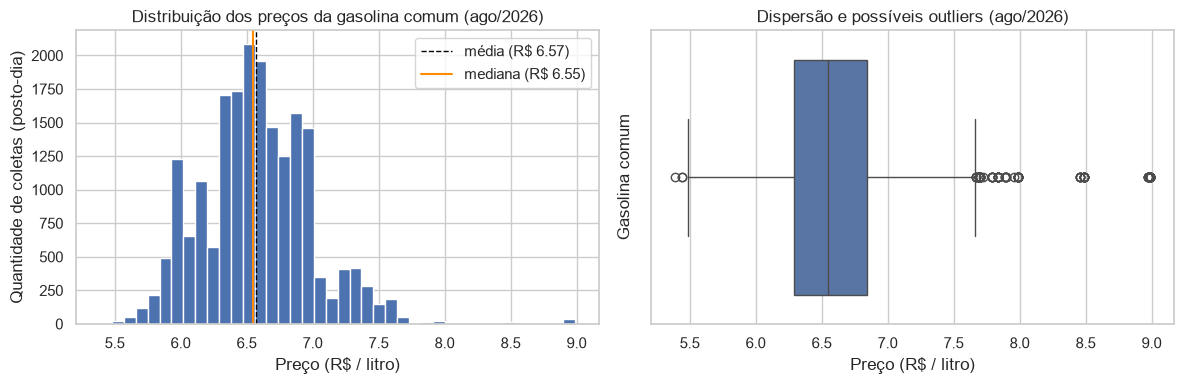

Limites do boxplot: R$ 5.46 a R$ 7.66
Possíveis outliers: 128 acima e 3 abaixo, de 19,803 coletas (0.7%)
Estados com mais preços acima do limite: SP 46, AM 33, BA 14, RO 8, PE 8


In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].hist(precos_ago, bins=40, edgecolor="white")
eixos[0].axvline(precos_ago.mean(), color="black", linestyle="--", linewidth=1, label=f"média (R$ {precos_ago.mean():.2f})")
eixos[0].axvline(precos_ago.median(), color="darkorange", linewidth=1.5, label=f"mediana (R$ {precos_ago.median():.2f})")
eixos[0].set(title="Distribuição dos preços da gasolina comum (ago/2026)",
             xlabel="Preço (R$ / litro)", ylabel="Quantidade de coletas (posto-dia)")
eixos[0].legend()
sns.boxplot(x=precos_ago, ax=eixos[1])
eixos[1].set(title="Dispersão e possíveis outliers (ago/2026)", xlabel="Preço (R$ / litro)", ylabel="Gasolina comum")
plt.tight_layout()
plt.show()

limite_inferior, limite_superior = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
acima = gasolina_ago[precos_ago > limite_superior]
abaixo = gasolina_ago[precos_ago < limite_inferior]
print(f"Limites do boxplot: R$ {limite_inferior:.2f} a R$ {limite_superior:.2f}")
print(f"Possíveis outliers: {len(acima)} acima e {len(abaixo)} abaixo, de {len(precos_ago):,} coletas ({(len(acima) + len(abaixo)) / len(precos_ago):.1%})")
print("Estados com mais preços acima do limite:", ", ".join(f"{uf} {n}" for uf, n in acima["uf"].value_counts().head(5).items()))

**Resposta do grupo:**

- **Tendência central:** em todos os produtos a média e a mediana são praticamente iguais (gasolina comum: R\$ 6,00 e R\$ 5,99 no período). Isso indica distribuições quase simétricas, sem valores extremos puxando a média, então a média é um bom resumo do preço típico. Em agosto/2026, a gasolina comum custava em média **R\$ 6,57**.
- **Diferença entre estados:** em agosto/2026, Minas Gerais tinha a gasolina mais barata (R\$ 6,28) e Roraima a mais cara (R\$ 7,57): **R\$ 1,28 por litro** de diferença. Os cinco estados mais caros são todos da região Norte, o que é coerente com o custo maior de transporte até lá.
- **Dispersão:** o coeficiente de variação fica entre 9% e 13%; o etanol é o produto que mais varia (13,4%). Dentro de uma mesma cidade e no mesmo dia, a diferença entre o posto mais caro e o mais barato é de **R\$ 0,34 por litro** na mediana e passa de **R\$ 0,90** em 10% dos casos. Num tanque de 50 litros, isso dá de R\$ 17 a R\$ 45 de diferença só pela escolha do posto, que é justamente a variação que o projeto investiga.
- **Distribuição:** metade dos preços de agosto/2026 está entre R\$ 6,29 e R\$ 6,84, e quase 70% ficam entre R\$ 6,25 e R\$ 7,00. Preços acima de R\$ 7,50 são raros (1,8%) e se concentram nos estados do Norte. O histograma tem forma de sino, um pouco mais alongada para a direita, com picos em preços terminados em 9 (como R\$ 6,49 e R\$ 6,99), o jeito mais comum de os postos marcarem o preço. O boxplot aponta 131 possíveis outliers (0,7% das coletas), quase todos acima de R\$ 7,66, principalmente em SP e no AM; como decidido no RA1, eles foram mantidos.
- **Um alerta:** Roraima tem desvio-padrão de apenas R\$ 0,01, porque a pesquisa cobre só um município do estado. A representatividade da amostra é discutida na seção 3.

## 2. Visualização e interpretação dos dados

Produza pelo menos três visualizações que ajudem a compreender diferentes características dos dados. Cada visualização deve ter variáveis e resultados identificados e uma breve interpretação: padrões, tendências, diferenças ou comportamentos relevantes.

Fizemos quatro visualizações, uma para cada pergunta do projeto que envolve comparação de preços: evolução no tempo (pergunta 5), diferença entre estados (pergunta 1), bandeira (pergunta 2) e etanol × gasolina (pergunta 4).

### 2.1 Evolução do preço ao longo do tempo

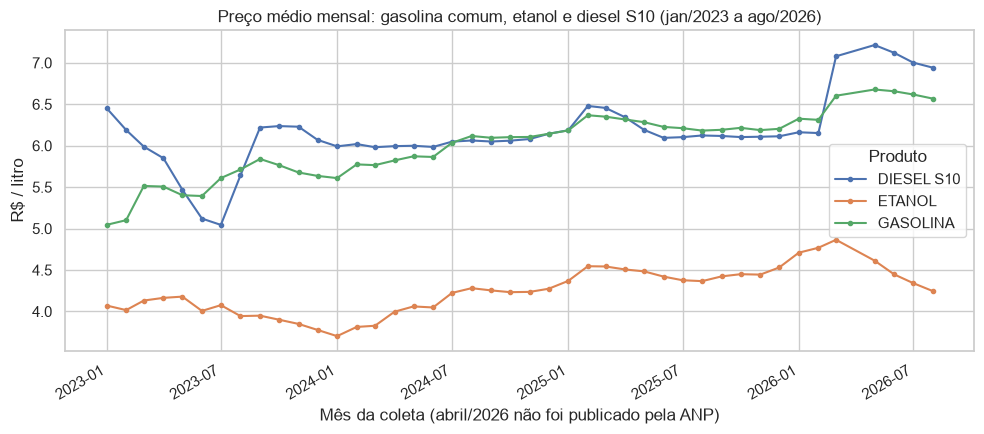

DIESEL S10  jan/2023: R$ 6.45 → ago/2026: R$ 6.94 (+8%)
ETANOL      jan/2023: R$ 4.07 → ago/2026: R$ 4.25 (+4%)
GASOLINA    jan/2023: R$ 5.04 → ago/2026: R$ 6.57 (+30%)


In [7]:
litro = df[df["produto"].isin(["GASOLINA", "ETANOL", "DIESEL S10"])].copy()
litro["mes"] = litro["data_coleta"].dt.to_period("M").dt.to_timestamp()
evolucao = litro.groupby(["mes", "produto"])["valor_venda"].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 4.5))
evolucao.plot(ax=ax, marker="o", markersize=3)
ax.set_title("Preço médio mensal: gasolina comum, etanol e diesel S10 (jan/2023 a ago/2026)")
ax.set_xlabel("Mês da coleta (abril/2026 não foi publicado pela ANP)")
ax.set_ylabel("R$ / litro")
ax.legend(title="Produto")
plt.tight_layout()
plt.show()

for produto in evolucao.columns:
    inicio, fim = evolucao[produto].iloc[0], evolucao[produto].iloc[-1]
    print(f"{produto:<11} jan/2023: R$ {inicio:.2f} → ago/2026: R$ {fim:.2f} ({(fim / inicio - 1) * 100:+.0f}%)")
del litro

**Interpretação:** a gasolina comum subiu de R\$ 5,04 (jan/2023) para R\$ 6,57 (ago/2026), uma alta de **30%**. A subida não foi contínua, mas em degraus, com saltos no começo de 2023, no segundo semestre de 2023 e em março de 2026, e períodos de estabilidade entre eles. O diesel S10 caiu no primeiro semestre de 2023, voltou a subir e deu um salto em março de 2026, chegando perto de R\$ 7,20. O etanol subiu só 4% no período e oscila mais: teve o pico em março de 2026 e caiu nos meses seguintes. É por isso que a vantagem do etanol muda com o tempo (2.4).

### 2.2 Diferença de preço entre os estados

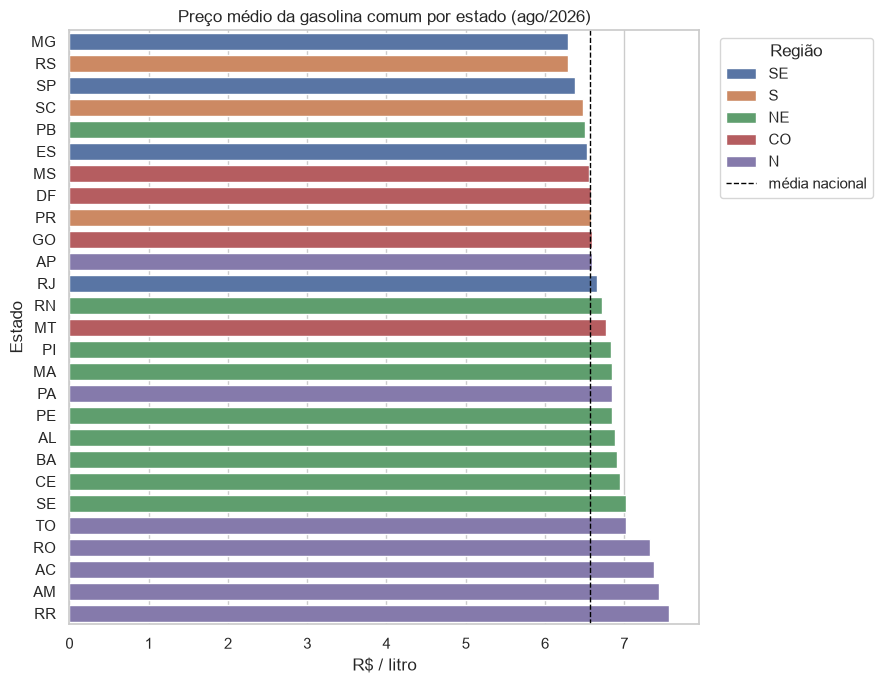

Preço médio por região (ago/2026):
   SE  R$ 6.40
   S   R$ 6.44
   CO  R$ 6.62
   NE  R$ 6.86
   N   R$ 7.13


In [8]:
media_uf = (gasolina_ago.groupby(["uf", "regiao"])["valor_venda"].mean()
            .reset_index().sort_values("valor_venda"))

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=media_uf, x="valor_venda", y="uf", hue="regiao", order=media_uf["uf"], dodge=False, ax=ax)
ax.axvline(gasolina_ago["valor_venda"].mean(), color="black", linestyle="--", linewidth=1, label="média nacional")
ax.set_title("Preço médio da gasolina comum por estado (ago/2026)")
ax.set_xlabel("R$ / litro")
ax.set_ylabel("Estado")
ax.legend(title="Região", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Preço médio por região (ago/2026):")
for regiao, valor in gasolina_ago.groupby("regiao")["valor_venda"].mean().sort_values().items():
    print(f"   {regiao:<3} R$ {valor:.2f}")

**Interpretação:** a gasolina é mais barata no Sudeste (R\$ 6,40) e no Sul (R\$ 6,44) e mais cara no Nordeste (R\$ 6,86) e no Norte (R\$ 7,13). Os quatro estados mais caros (RO, AC, AM e RR) ficam no Norte, longe dos grandes centros. Mas a região não explica tudo: a Paraíba, no Nordeste, está entre os cinco estados mais baratos.

### 2.3 Posto com bandeira × posto de bandeira branca

Comparar o Brasil inteiro misturaria o efeito do estado com o da bandeira, porque a proporção de postos de bandeira branca muda de um estado para outro. Por isso calculamos a diferença **dentro de cada estado**, com as coletas de janeiro a agosto de 2026.

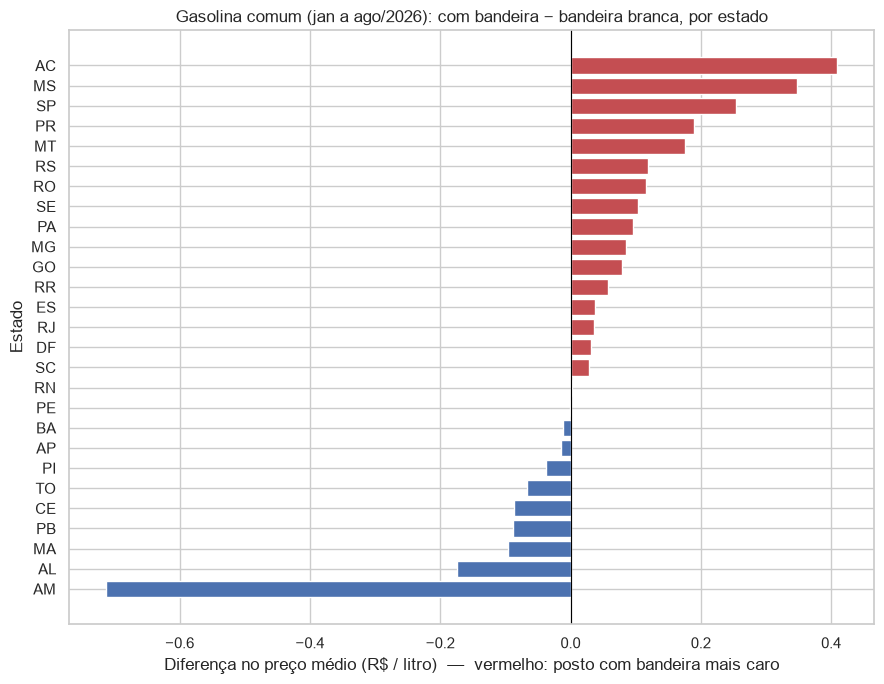

Estados em que o posto com bandeira é mais caro: 17 de 27
Onde o posto com bandeira é mais caro: AC (+0.41), MS (+0.35), SP (+0.25)
Onde o posto de bandeira branca é mais caro: AM (-0.71), AL (-0.17), MA (-0.10)


In [9]:
gasolina_2026 = gasolina_comum[gasolina_comum["data_coleta"] >= "2026-01-01"].copy()
gasolina_2026["tipo_posto"] = np.where(gasolina_2026["bandeira"] == "BRANCA", "bandeira branca", "com bandeira")

media_tipo = gasolina_2026.groupby(["uf", "tipo_posto"])["valor_venda"].mean().unstack()
media_tipo["diferença"] = media_tipo["com bandeira"] - media_tipo["bandeira branca"]
media_tipo = media_tipo.sort_values("diferença")

cores = np.where(media_tipo["diferença"] > 0, "#C44E52", "#4C72B0")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(media_tipo.index, media_tipo["diferença"], color=cores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Gasolina comum (jan a ago/2026): com bandeira − bandeira branca, por estado")
ax.set_xlabel("Diferença no preço médio (R$ / litro)  —  vermelho: posto com bandeira mais caro")
ax.set_ylabel("Estado")
plt.tight_layout()
plt.show()

print(f"Estados em que o posto com bandeira é mais caro: {(media_tipo['diferença'] > 0).sum()} de {len(media_tipo)}")
print(f"Onde o posto com bandeira é mais caro: "
      f"{', '.join(f'{uf} ({v:+.2f})' for uf, v in media_tipo['diferença'].tail(3)[::-1].items())}")
print(f"Onde o posto de bandeira branca é mais caro: "
      f"{', '.join(f'{uf} ({v:+.2f})' for uf, v in media_tipo['diferença'].head(3).items())}")

**Interpretação:** em **17 dos 27 estados** o posto com bandeira cobra mais caro que o de bandeira branca, com as maiores diferenças no Acre (+R\$ 0,41), em Mato Grosso do Sul (+R\$ 0,35) e em São Paulo (+R\$ 0,25). Nos outros 10, a maioria do Nordeste, a diferença é quase zero (PE e RN) ou o contrário acontece: no Amazonas, o posto de bandeira branca é R\$ 0,71 mais caro. Ou seja, a bandeira está associada ao preço, mas o efeito depende do estado. No Acre a comparação usa poucas coletas de bandeira branca (26), então deve ser vista com cuidado.

### 2.4 Onde o etanol compensa

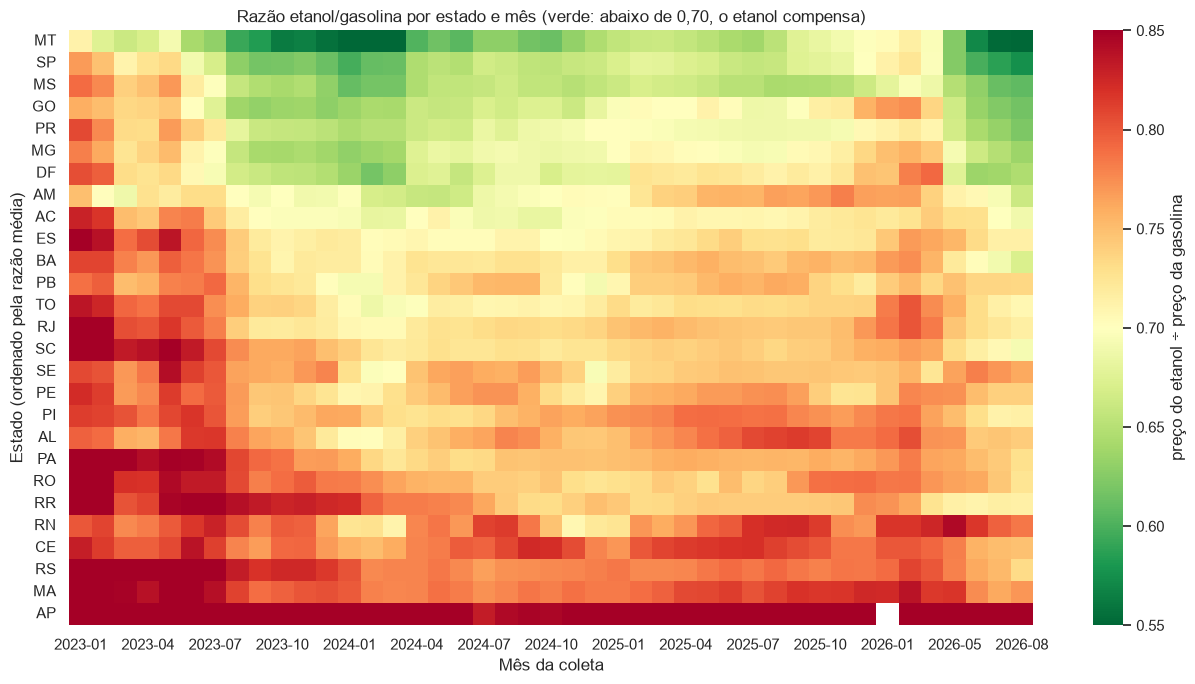

Meses em que o etanol compensou (de 43): MT 40, MS 37, SP 36, PR 30, GO 26, MG 25
Estados em que nunca compensou: RJ, PE, PI, AL, PA, RO, RR, RN, CE, RS, MA, AP


In [10]:
etanol_gasolina = df[df["produto"].isin(["ETANOL", "GASOLINA"])].copy()
etanol_gasolina["mes"] = etanol_gasolina["data_coleta"].dt.strftime("%Y-%m")
medias = etanol_gasolina.groupby(["uf", "mes", "produto"])["valor_venda"].mean().unstack()
razao = (medias["ETANOL"] / medias["GASOLINA"]).unstack("mes")
razao = razao.loc[razao.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(razao, cmap="RdYlGn_r", center=0.70, vmin=0.55, vmax=0.85, xticklabels=3,
            cbar_kws={"label": "preço do etanol ÷ preço da gasolina"}, ax=ax)
ax.set_title("Razão etanol/gasolina por estado e mês (verde: abaixo de 0,70, o etanol compensa)")
ax.set_xlabel("Mês da coleta")
ax.set_ylabel("Estado (ordenado pela razão média)")
ax.grid(False)
plt.tight_layout()
plt.show()

compensa = (razao < 0.70).sum(axis=1).sort_values(ascending=False)
print(f"Meses em que o etanol compensou (de {razao.shape[1]}): "
      f"{', '.join(f'{uf} {n}' for uf, n in compensa.head(6).items())}")
print(f"Estados em que nunca compensou: {', '.join(compensa[compensa == 0].index)}")
del etanol_gasolina

**Interpretação:** o etanol compensa (verde) de forma consistente em MT, SP, MS, GO e PR, estados do Centro-Sul, região que concentra a produção de etanol de cana. Em 12 estados a razão nunca ficou abaixo de 0,70: a maioria do Norte e do Nordeste, mas também RJ e RS. Há ainda um padrão no tempo: no início de 2023 o etanol não compensava em quase nenhum estado; a situação melhorou a partir do segundo semestre de 2023, piorou no começo de 2026, quando o etanol subiu, e voltou a melhorar a partir de maio/2026. A célula em branco é o Amapá em janeiro/2026, sem coleta de etanol.

## 3. Amostragem e representatividade

Analise brevemente:

- a origem e a abrangência do conjunto de dados;
- se os registros representam adequadamente o problema investigado;
- possíveis limitações ou vieses que possam influenciar os resultados.

O Levantamento de Preços da ANP já é uma amostra: a ANP escolhe os municípios e os postos que serão pesquisados. Verificamos até onde essa amostra chega, como ela se distribui entre as cidades e se muda ao longo do tempo.

In [11]:
municipios = df[["uf", "municipio"]].drop_duplicates()
municipios_por_uf = municipios.groupby("uf").size().sort_values()

print("ABRANGÊNCIA DA BASE")
print("─" * 50)
print(f"Estados:    {df['uf'].nunique()} de 27")
print(f"Municípios: {len(municipios)} de 5.570 do Brasil ({len(municipios) / 5570:.1%})")
print(f"Postos:     {df['cnpj'].nunique():,} (CNPJ diferentes)")
print(f"Período:    jan/2023 a ago/2026, {df['data_coleta'].dt.strftime('%Y-%m').nunique()} meses (sem abril/2026)\n")

print("Municípios pesquisados por estado:")
print(", ".join(f"{uf} {n}" for uf, n in municipios_por_uf.items()))
poucos = municipios_por_uf[municipios_por_uf <= 2].index
print("\nEstados com só 1 ou 2 municípios: " + "; ".join(
    f"{uf} ({', '.join(sorted(municipios.loc[municipios['uf'] == uf, 'municipio']))})" for uf in poucos))

ABRANGÊNCIA DA BASE
──────────────────────────────────────────────────
Estados:    27 de 27
Municípios: 472 de 5.570 do Brasil (8.5%)
Postos:     21,645 (CNPJ diferentes)


Período:    jan/2023 a ago/2026, 43 meses (sem abril/2026)

Municípios pesquisados por estado:
DF 1, RR 1, AP 2, AC 2, SE 4, RN 4, PI 4, AL 5, AM 5, TO 5, RO 6, PB 6, MS 7, MT 8, ES 10, CE 13, MA 13, PA 16, GO 17, PE 18, SC 22, PR 32, RJ 32, BA 33, RS 37, MG 59, SP 110

Estados com só 1 ou 2 municípios: DF (BRASILIA); RR (BOA VISTA); AP (MACAPA, SANTANA); AC (CRUZEIRO DO SUL, RIO BRANCO)


In [12]:
coletas_municipio = df.groupby(["uf", "municipio"]).size().sort_values(ascending=False)
postos_municipio = df.groupby(["uf", "municipio"])["cnpj"].nunique()

print("CONCENTRAÇÃO DAS COLETAS")
print("─" * 50)
print(f"Os 27 municípios com mais coletas concentram {coletas_municipio.head(27).sum() / coletas_municipio.sum():.0%} de todas as coletas")
print(f"Mediana de postos pesquisados por município: {postos_municipio.median():.0f}\n")
print("Municípios com mais coletas:")
display(coletas_municipio.head(5).to_frame("coletas").style.format("{:,}"))

CONCENTRAÇÃO DAS COLETAS
──────────────────────────────────────────────────
Os 27 municípios com mais coletas concentram 21% de todas as coletas
Mediana de postos pesquisados por município: 32

Municípios com mais coletas:


,,coletas
uf,municipio,
SP,SAO PAULO,"151,275"
RJ,RIO DE JANEIRO,"65,276"
AM,MANAUS,"41,140"
DF,BRASILIA,"38,294"
PR,CURITIBA,"37,851"


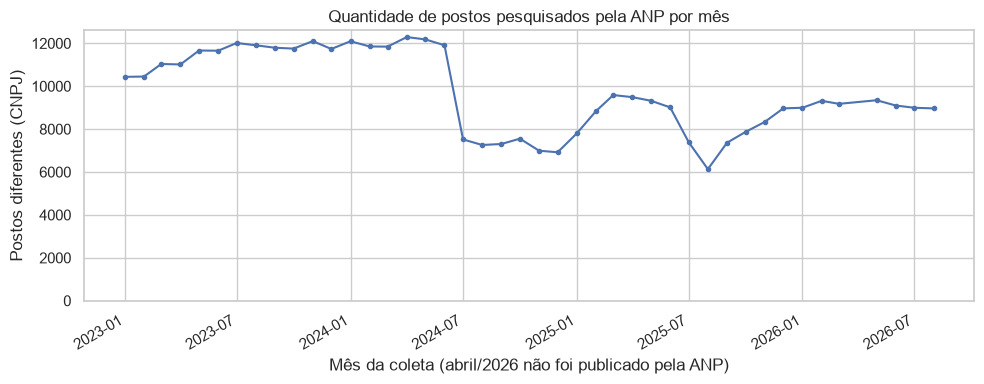

COBERTURA AO LONGO DO TEMPO
──────────────────────────────────────────────────
Mais postos: 12,290 em 04/2024 | menos postos: 6,133 em 08/2025
Postos presentes em pelo menos metade dos 43 meses: 8,522 (39%)
Postos que aparecem em um único mês: 1,365

Amapá, coletas de gasolina comum: 2025-11: 44, 2025-12: 44, 2026-01: 2, 2026-02: 40, 2026-03: 24


In [13]:
mes = df["data_coleta"].dt.to_period("M")
postos_por_mes = df["cnpj"].groupby(mes).nunique()
postos_por_mes.index = postos_por_mes.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4))
postos_por_mes.plot(ax=ax, marker="o", markersize=3)
ax.set_title("Quantidade de postos pesquisados pela ANP por mês")
ax.set_xlabel("Mês da coleta (abril/2026 não foi publicado pela ANP)")
ax.set_ylabel("Postos diferentes (CNPJ)")
ax.set_ylim(0, None)
plt.tight_layout()
plt.show()

meses_por_posto = mes.groupby(df["cnpj"]).nunique()
total_meses = mes.nunique()
print("COBERTURA AO LONGO DO TEMPO")
print("─" * 50)
print(f"Mais postos: {postos_por_mes.max():,} em {postos_por_mes.idxmax():%m/%Y} | menos postos: {postos_por_mes.min():,} em {postos_por_mes.idxmin():%m/%Y}")
print(f"Postos presentes em pelo menos metade dos {total_meses} meses: {(meses_por_posto >= total_meses / 2).sum():,} "
      f"({(meses_por_posto >= total_meses / 2).mean():.0%})")
print(f"Postos que aparecem em um único mês: {(meses_por_posto == 1).sum():,}")

amapa = df[(df["uf"] == "AP") & (df["produto"] == "GASOLINA")]
coletas_amapa = amapa.groupby(amapa["data_coleta"].dt.strftime("%Y-%m")).size()
print("\nAmapá, coletas de gasolina comum: " + ", ".join(f"{m}: {n}" for m, n in coletas_amapa.loc["2025-11":"2026-03"].items()))
del mes

**Resposta do grupo:**

- **População e amostra:** a população que interessa ao projeto são todos os postos de combustível do Brasil; a amostra são os postos que a ANP pesquisa.
- **Origem e abrangência:** os dados vêm do Levantamento de Preços de Combustíveis da ANP, uma pesquisa por amostragem em que a ANP escolhe os municípios e os postos. A base cobre os 27 estados, mas só **472 dos 5.570 municípios (8,5%)**, com 21.645 postos, de janeiro/2023 a agosto/2026.
- **Os dados representam o problema?** Para a pergunta central, a diferença de preço entre postos, sim, principalmente nas cidades maiores: a mediana é de 32 postos pesquisados por município, o que permite comparar postos da mesma cidade no mesmo dia (seção 1). Para o Brasil como um todo, a base representa melhor as cidades grandes e médias: os 27 municípios com mais coletas concentram 21% delas.
- **Limitações e vieses:**
    - os municípios pequenos ficam de fora, e neles o preço pode ser diferente, por exemplo pela menor concorrência. Isso é um **viés de seleção**: a forma de escolher os postos favorece as cidades maiores. E **uma amostra grande ainda pode ser enviesada**: são 3,7 milhões de preços, mas o tamanho da base não corrige essa concentração;
    - em RR e no DF a pesquisa cobre um único município (Boa Vista e Brasília) e, no AP e no AC, só dois. Nesses estados o "preço do estado" é, na prática, o preço de uma ou duas cidades, e por isso Roraima tem desvio-padrão quase zero (seção 1);
    - a cobertura muda com o tempo: eram cerca de 12 mil postos por mês até junho/2024, que caíram para cerca de 7 mil a partir de julho/2024 e oscilaram entre 6 e 9,6 mil depois. Quando a amostra muda, parte da variação da média mensal pode vir da troca de postos, e não do preço;
    - os postos se revezam: só 39% aparecem em pelo menos metade dos meses;
    - abril/2026 não foi publicado, e no Amapá, em janeiro/2026, houve só 2 coletas de gasolina.
- **Amostragem:** não sorteamos uma amostra; usamos a base inteira (3,7 milhões de preços), que já é a amostra feita pela ANP. Os critérios de escolha dos postos não estão na base. No RA2, os dados foram simulados e servem só para demonstrar o streaming.

## 4. Aplicação de Machine Learning

Aplicação simples de aprendizagem supervisionada, com:

1. definição do problema preditivo;
2. variável-alvo (*target*) e características (*features*);
3. separação dos dados em treino e teste;
4. treinamento de um modelo e previsões;
5. avaliação com pelo menos uma métrica adequada.

**Resposta do grupo:**

**Problema preditivo (regressão):** estimar o preço da gasolina comum em um posto, em R\$/litro, a partir do estado, da bandeira e do mês da coleta. Além de prever, o modelo mostra quanto do preço esses fatores explicam e quanto sobra para a diferença entre postos, que é a pergunta central do projeto.

- **Target:** `valor_venda` da gasolina comum.
- **Features:** `uf` (estado), `bandeira_grupo` (as 5 bandeiras com mais coletas e `OUTRAS`) e `meses` (meses desde janeiro/2023, para captar a tendência no tempo).

Usamos só a gasolina comum porque cada produto tem um nível de preço diferente e o GLP e o GNV nem estão em litro (RA1).

In [14]:
gasolina = df[df["produto"] == "GASOLINA"].copy()

principais = gasolina["bandeira"].value_counts().head(5).index
gasolina["bandeira_grupo"] = gasolina["bandeira"].where(gasolina["bandeira"].isin(principais), "OUTRAS")
gasolina["meses"] = (gasolina["data_coleta"].dt.year - 2023) * 12 + gasolina["data_coleta"].dt.month - 1

# Estado e bandeira viram colunas 0/1; SP e BRANCA ficam como referência
X = pd.get_dummies(gasolina[["uf", "bandeira_grupo"]].astype(str), dtype="int8")
X = X.drop(columns=["uf_SP", "bandeira_grupo_BRANCA"])
X["meses"] = gasolina["meses"].values
y = gasolina["valor_venda"]

print(f"Registros de gasolina comum: {len(X):,}")
print(f"Features: {X.shape[1]} colunas (26 estados + 5 bandeiras + meses)")
print("Bandeiras com mais coletas:", ", ".join(principais))

Registros de gasolina comum: 808,704
Features: 32 colunas (26 estados + 5 bandeiras + meses)
Bandeiras com mais coletas: BRANCA, VIBRA, IPIRANGA, RAIZEN, ALE


**Separação em treino e teste:** a divisão é pelo tempo. O modelo aprende com 2023 a 2025 e é avaliado em janeiro a agosto de 2026, meses que ele nunca viu, como se estivesse prevendo o futuro. Fizemos assim porque o preço muda com o tempo: o padrão aprendido no passado pode não valer do mesmo jeito no futuro, o que a aula chamou de *concept drift*. Uma divisão aleatória colocaria o mesmo posto, no mesmo mês, no treino e no teste, e o resultado ficaria otimista; mais abaixo comparamos as duas formas.

In [15]:
treino = gasolina["data_coleta"] < "2026-01-01"

X_treino, X_teste = X[treino], X[~treino]
y_treino, y_teste = y[treino], y[~treino]

print(f"Treino (2023 a 2025):  {len(X_treino):,} registros ({treino.mean():.0%})")
print(f"Teste  (jan-ago/2026): {len(X_teste):,} registros ({(~treino).mean():.0%})")

Treino (2023 a 2025):  677,508 registros (84%)
Teste  (jan-ago/2026): 131,196 registros (16%)


**Treinamento e avaliação:** usamos uma **regressão linear**. Para saber se o modelo é útil, comparamos com uma referência simples: repetir, para 2026, o preço médio de cada estado em dezembro/2025, o último mês do treino.

A métrica principal é o **MAE** (erro absoluto médio), que fica na mesma unidade do preço: quantos centavos por litro o modelo erra, em média. O **R²** mostra quanto da variação dos preços o modelo explica (1 = tudo, 0 = nada).

In [16]:
media_dez_2025 = gasolina[treino & (gasolina["data_coleta"] >= "2025-12-01")].groupby("uf")["valor_venda"].mean()
previsao_referencia = gasolina.loc[~treino, "uf"].map(media_dez_2025)

regressao = LinearRegression()
regressao.fit(X_treino, y_treino)
previsao_regressao = regressao.predict(X_teste)

resultados = pd.DataFrame({
    "modelo": ["Referência: média do estado em dez/2025", "Regressão linear"],
    "MAE (R$/litro)": [mean_absolute_error(y_teste, previsao_referencia), mean_absolute_error(y_teste, previsao_regressao)],
    "R²": [r2_score(y_teste, previsao_referencia), r2_score(y_teste, previsao_regressao)],
})
print("AVALIAÇÃO NO TESTE (jan-ago/2026)")
print("─" * 50)
display(resultados.style.format({"MAE (R$/litro)": "{:.2f}", "R²": "{:.2f}"}).hide(axis="index"))

AVALIAÇÃO NO TESTE (jan-ago/2026)
──────────────────────────────────────────────────


modelo,MAE (R$/litro),R²
Referência: média do estado em dez/2025,0.41,-0.48
Regressão linear,0.28,0.28


**Comparação com a divisão aleatória da aula:** treinamos o mesmo modelo com `train_test_split` (80% treino e 20% teste, `random_state=42`), como no notebook de Machine Learning da disciplina, para comparar com a divisão pelo tempo.

In [17]:
X_treino_aleatorio, X_teste_aleatorio, y_treino_aleatorio, y_teste_aleatorio = train_test_split(
    X, y, test_size=0.20, random_state=42,
)
regressao_aleatoria = LinearRegression().fit(X_treino_aleatorio, y_treino_aleatorio)
previsao_aleatoria = regressao_aleatoria.predict(X_teste_aleatorio)

divisoes = pd.DataFrame({
    "divisão": ["Pelo tempo (treino 2023-2025, teste 2026)", "Aleatória 80/20 (train_test_split)"],
    "MAE (R$/litro)": [mean_absolute_error(y_teste, previsao_regressao),
                       mean_absolute_error(y_teste_aleatorio, previsao_aleatoria)],
    "R²": [r2_score(y_teste, previsao_regressao), r2_score(y_teste_aleatorio, previsao_aleatoria)],
})
display(divisoes.style.format({"MAE (R$/litro)": "{:.2f}", "R²": "{:.2f}"}).hide(axis="index"))

divisão,MAE (R$/litro),R²
"Pelo tempo (treino 2023-2025, teste 2026)",0.28,0.28
Aleatória 80/20 (train_test_split),0.26,0.60


Na divisão aleatória o erro é menor e o R² maior, mas esse resultado é otimista: o teste tem coletas dos mesmos meses que o treino, então o modelo já "viu" o nível de preço daquele período. Para o nosso uso, prever meses que ainda não aconteceram, a avaliação honesta é a divisão pelo tempo, que mantivemos como principal.

In [18]:
coeficientes = pd.Series(regressao.coef_, index=X.columns)
bandeiras = (coeficientes.filter(like="bandeira_grupo_")
             .rename(lambda nome: nome.replace("bandeira_grupo_", ""))
             .sort_values(ascending=False))

print("Diferença em relação a um posto de bandeira BRANCA, no mesmo estado e mês:")
for nome, valor in bandeiras.items():
    print(f"   {nome:<10} {valor:+.2f} R$/litro")
print(f"\nTendência no tempo: {coeficientes['meses']:+.3f} R$/litro por mês ({coeficientes['meses'] * 12:+.2f} por ano)")

Diferença em relação a um posto de bandeira BRANCA, no mesmo estado e mês:
   VIBRA      +0.18 R$/litro
   IPIRANGA   +0.17 R$/litro
   RAIZEN     +0.15 R$/litro
   ALE        +0.11 R$/litro
   OUTRAS     +0.09 R$/litro

Tendência no tempo: +0.030 R$/litro por mês (+0.36 por ano)


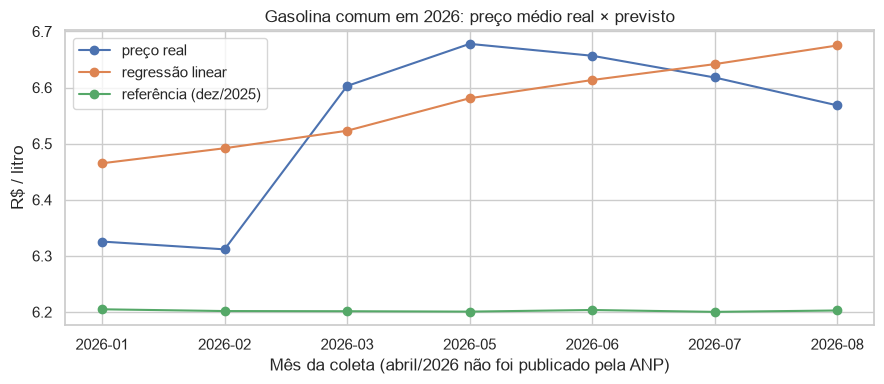

In [19]:
comparacao = pd.DataFrame({
    "mes": gasolina.loc[~treino, "data_coleta"].dt.strftime("%Y-%m").values,
    "preço real": y_teste.values,
    "regressão linear": previsao_regressao,
    "referência (dez/2025)": previsao_referencia.values,
}).groupby("mes").mean()

ax = comparacao.plot(marker="o", figsize=(9, 4))
ax.set_title("Gasolina comum em 2026: preço médio real × previsto")
ax.set_xlabel("Mês da coleta (abril/2026 não foi publicado pela ANP)")
ax.set_ylabel("R$ / litro")
plt.tight_layout()
plt.show()

**Resposta do grupo:**

- **Desempenho:** a regressão linear erra, em média, **R\$ 0,28 por litro** nos meses de 2026, contra R\$ 0,41 da referência que repete o preço de dezembro/2025. O modelo acerta o nível de preço de cada estado e a tendência de alta, que a referência não acompanha.
- **O que o modelo não explica:** o R² de 0,28 mostra que estado, bandeira e mês explicam só uma parte da variação. O resto está em fatores que não existem na base, como a concorrência no bairro, o custo de cada posto e promoções. Isso conversa com a pergunta central: estado e bandeira importam, mas não explicam tudo.
- **Bandeira (pergunta 2):** no mesmo estado e mês, postos com bandeira cobram de **R\$ 0,09 a R\$ 0,18 a mais** por litro que postos de bandeira branca. É uma associação, não uma causa.
- **Divisão aleatória × pelo tempo:** com a divisão aleatória 80/20 usada na aula, o MAE cai para R\$ 0,26 e o R² sobe para 0,60, mas esse resultado é otimista, porque o modelo já viu os mesmos meses no treino. Mantivemos a divisão pelo tempo como avaliação principal, porque o objetivo é prever meses futuros e o padrão dos preços muda com o tempo.
- **Limitações:** o modelo segue uma tendência em linha reta. Em janeiro e fevereiro ele previu um preço mais alto que o real, em março o preço deu um salto que a linha reta não acompanha e, de junho a agosto, o preço começou a cair enquanto o modelo continuou subindo. Mudanças bruscas, como alteração de imposto ou de preço nas refinarias, não estão entre as features.

## 5. Conclusões

Apresente uma conclusão geral do RA3, contemplando:

- os principais resultados das análises estatísticas e das visualizações;
- a interpretação do desempenho do modelo de Machine Learning;
- as limitações dos dados e das análises;
- a relação dos resultados com o problema definido no projeto.

**Resposta do grupo:**

**Principais resultados.** Voltando às perguntas do projeto:

1. **Diferença entre estados:** em agosto/2026, a gasolina comum ia de R\$ 6,28 (MG) a R\$ 7,57 (RR), uma diferença de R\$ 1,28 por litro. O Sudeste e o Sul são as regiões mais baratas e o Norte, a mais cara.
2. **Bandeira:** em 17 dos 27 estados o posto com bandeira cobra mais que o de bandeira branca, mas o efeito depende do estado; no Nordeste ele quase some ou se inverte.
3. **Diferença dentro da mesma cidade:** no mesmo dia, o posto mais caro cobra R\$ 0,34 a mais por litro que o mais barato (mediana), e em 10% dos casos mais de R\$ 0,90. Num tanque de 50 litros, isso dá de R\$ 17 a R\$ 45.
4. **Etanol:** compensa de forma consistente em MT, MS e SP, estados do Centro-Sul, e nunca compensou em 12 estados, a maioria do Norte e do Nordeste.
5. **Evolução:** de janeiro/2023 a agosto/2026, a gasolina subiu 30%, em degraus. O etanol subiu só 4%, mas oscila mais, e por isso a vantagem dele muda com o tempo.

**Machine Learning.** A regressão linear prevê o preço da gasolina de 2026 com erro médio de R\$ 0,28 por litro, melhor que repetir o preço de dezembro/2025 (R\$ 0,41). Ela confirma o que os gráficos mostram: no mesmo estado e mês, postos com bandeira cobram de R\$ 0,09 a R\$ 0,18 a mais. Mas o R² de 0,28 mostra que estado, bandeira e mês explicam só uma parte da variação; o resto está em fatores que a base não tem, como a concorrência no bairro e o custo de cada posto. Com a divisão aleatória 80/20 da aula, o erro seria menor (R\$ 0,26), mas otimista, porque o teste teria os mesmos meses do treino.

**Limitações.**

- A pesquisa da ANP cobre 472 dos 5.570 municípios e representa melhor as cidades grandes e médias. Em RR e no DF, o "preço do estado" é o de uma única cidade.
- O número de postos pesquisados caiu de cerca de 12 mil para 7 mil por mês a partir de julho/2024, o que pode afetar as comparações no tempo. Abril/2026 não foi publicado.
- As análises mostram associações, e não causas: não temos dados de imposto, frete ou custo de cada posto.
- O modelo segue uma tendência em linha reta e não acompanha mudanças bruscas de preço.

**Relação com o problema.** A pergunta central era quais fatores estão associados à variação do preço entre os postos brasileiros. Os resultados mostram três níveis: o **estado** (até R\$ 1,28 por litro), o **tempo** (alta de 30% em três anos e meio) e a **bandeira** (alguns centavos, dependendo do estado). Mesmo considerando tudo isso, sobra uma diferença grande entre postos da mesma cidade, no mesmo dia. Para o consumidor, a principal mensagem é que **pesquisar entre os postos da própria cidade pode economizar mais do que a diferença associada à bandeira**.